<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/04_portfolio_backtest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 - Backtest on the 50/50 S&P 500 / Apple portfolio

Same rules as 02. The 5 models of 02 applied to the portfolio return, plus 3 that look at both assets: EWMA (RiskMetrics, lambda 0.94), multivariate FHS (one GARCH per asset, joint residuals) and DCC-FHS (same, with the DCC correlation of 03). Takes about a minute.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/var-es-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from risk import *

prices = pd.concat({"spx": load_close("../black-scholes-sp500/data/sp500.csv"),
                    "aapl": load_close("data/aapl.csv")}, axis=1).dropna()
rets = np.log(prices).diff().dropna()
simple = np.exp(rets) - 1
w = np.array([0.5, 0.5])
port = np.log1p(simple @ w)   # 50/50, rebalanced every day
len(rets), rets.index[0].date(), rets.index[-1].date()

(6761, datetime.date(2000, 1, 4), datetime.date(2026, 11, 19))

In [3]:
bt = pd.concat([backtest(port), portfolio_backtest(rets, w).drop(columns="ret")], axis=1)
names = {"normal": "normal", "hist": "historical", "garch": "garch", "fhs": "FHS", "evt": "garch-EVT",
         "ewma": "EWMA", "mfhs": "multivariate FHS", "dcc": "DCC-FHS"}
def summary(bt, models):
    for m in models:
        breach = bt["ret"] < -bt[f"var_{m}"]
        ratio = (-bt["ret"][breach]).mean() / bt[f"es_{m}"][breach].mean()
        print(f"{names[m]:17s} {breach.sum():4d} breaches ({100*breach.mean():.2f}%)  "
              f"kupiec p={kupiec(breach.values)[1]:.3f}  christoffersen p={christoffersen(breach.values)[1]:.3f}  "
              f"loss/ES={ratio:.2f}")

print(len(bt), "days, expected", round(0.01 * len(bt)), "breaches")
summary(bt, names)
# normal / garch / EWMA (normal law): ~1.9% breaches, ES 14-28% too low
# historical 1.3% but clustered
# FHS / EVT / multivariate FHS: ES right, independent, but ~1.3% -> kupiec rejects or borderline
# DCC-FHS: 1.20%, passes both, ES 1.01 -> the only one that passes on the full period

5761 days, expected 58 breaches
normal             109 breaches (1.89%)  kupiec p=0.000  christoffersen p=0.000  loss/ES=1.28
historical          76 breaches (1.32%)  kupiec p=0.020  christoffersen p=0.000  loss/ES=1.03
garch              109 breaches (1.89%)  kupiec p=0.000  christoffersen p=0.532  loss/ES=1.14
FHS                 78 breaches (1.35%)  kupiec p=0.010  christoffersen p=0.406  loss/ES=1.02
garch-EVT           73 breaches (1.27%)  kupiec p=0.050  christoffersen p=0.326  loss/ES=1.04
EWMA               106 breaches (1.84%)  kupiec p=0.000  christoffersen p=0.477  loss/ES=1.18
multivariate FHS    74 breaches (1.28%)  kupiec p=0.038  christoffersen p=0.341  loss/ES=1.00
DCC-FHS             69 breaches (1.20%)  kupiec p=0.144  christoffersen p=0.268  loss/ES=1.01


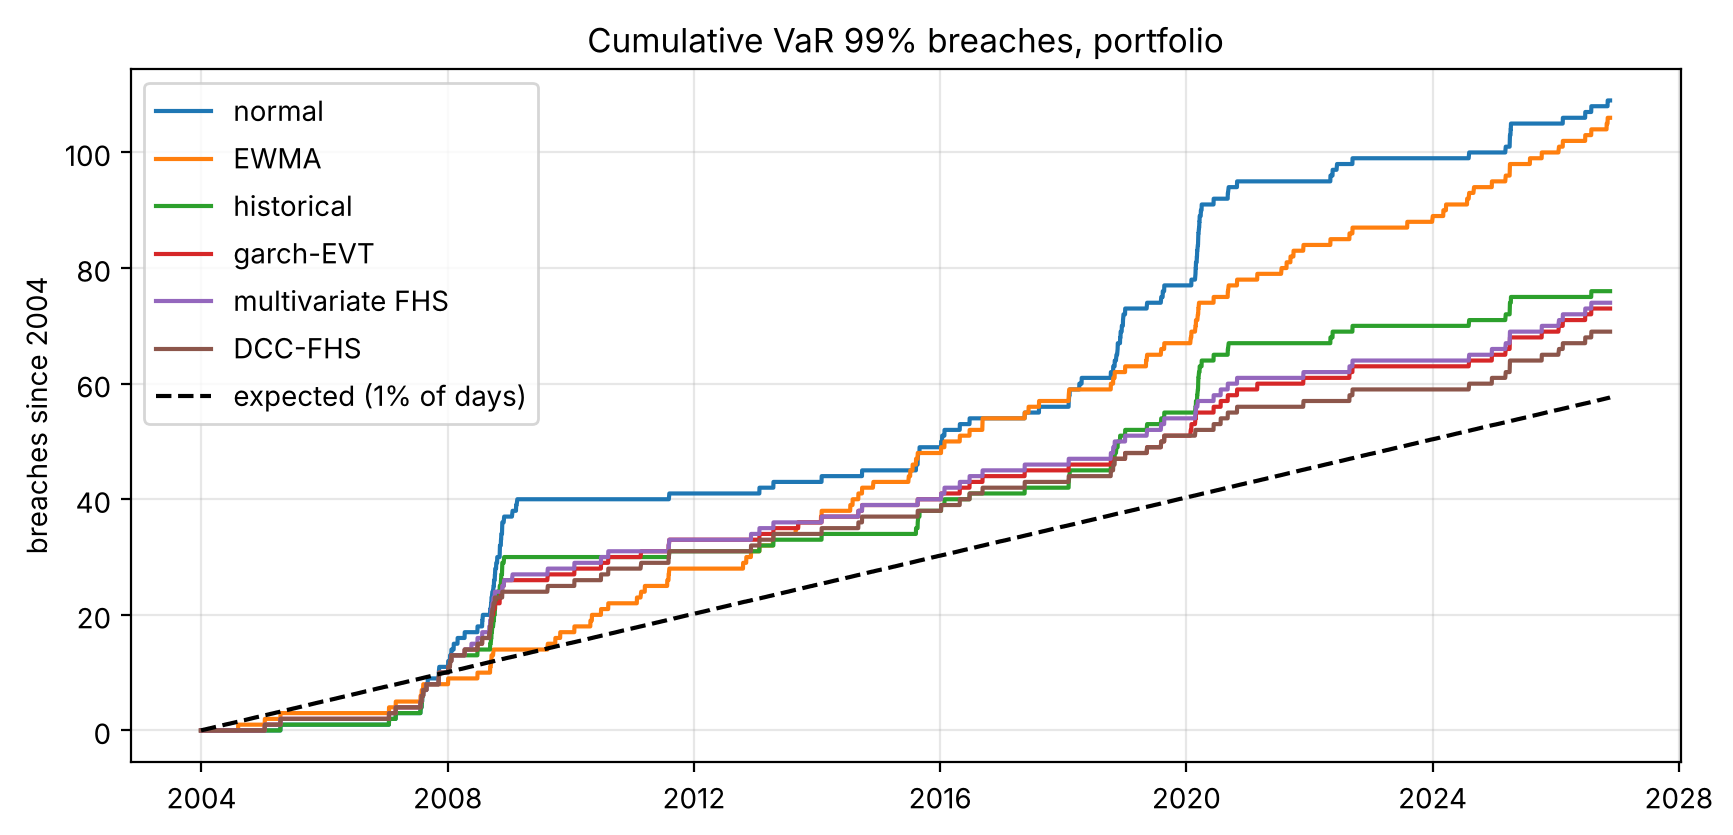

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for m in ["normal", "ewma", "hist", "evt", "mfhs", "dcc"]:
    breach = bt["ret"] < -bt[f"var_{m}"]
    ax.plot(breach.cumsum(), label=names[m])
ax.plot(bt.index, 0.01 * np.arange(1, len(bt) + 1), "k--", label="expected (1% of days)")
ax.set_ylabel("breaches since 2004")
ax.set_title("Cumulative VaR 99% breaches, portfolio")
ax.grid(alpha=0.3)
ax.legend()
plt.show()
# everything jumps in 2008

In [5]:
for m in ["fhs", "evt", "mfhs", "dcc"]:
    breach = bt["ret"] < -bt[f"var_{m}"]
    rest = breach[breach.index.year != 2008]
    print(f"{names[m]:17s} 2008: {breach.loc['2008'].sum():3d}   without 2008: {100*rest.mean():.2f}%  kupiec p={kupiec(rest.values)[1]:.3f}")
# all the extra breaches come from 2008. without it these models are at 1.0-1.1%
# autumn 2008: both crashed together and the correlation jumped faster than the models could follow
# dcc helps a bit (14 breaches in 2008 vs 16 for multivariate FHS), not enough

FHS               2008:  18   without 2008: 1.09%  kupiec p=0.511
garch-EVT         2008:  16   without 2008: 1.03%  kupiec p=0.796
multivariate FHS  2008:  16   without 2008: 1.05%  kupiec p=0.695
DCC-FHS           2008:  14   without 2008: 1.00%  kupiec p=0.991
